# dots.mocr — 3B Multimodal Vision-Language Model Layout Analysis Pipeline

Pipeline phân tích layout tài liệu bằng mô hình thị giác - ngôn ngữ đa phương thức **dots.mocr** (3B tham số, phát triển bởi nhóm nghiên cứu **RedNote HI Lab / Dots Studio**).

### Kiến trúc Vision-Language Model (VLM)
- **Backbone**: Mô hình Transformer thị giác - ngôn ngữ đa phương thức 3B tham số tối ưu hóa (Qwen2-VL backbone), hỗ trợ xử lý độ phân giải cao và hiểu sâu ngữ cảnh tài liệu.
- **End-to-End Layout Parsing**: Mô hình sinh trực tiếp cấu trúc layout tài liệu dạng JSON gồm danh sách bounding box `[x1, y1, x2, y2]` và nhãn phân loại tương ứng thông qua text prompt có cấu trúc.
- **Taxonomy Mapping (1-1)**: dots.mocr hỗ trợ trực tiếp 11 danh mục chuẩn của **DocLayNet** (`Caption`, `Footnote`, `Formula`, `List-item`, `Page-footer`, `Page-header`, `Picture`, `Section-header`, `Table`, `Text`, `Title`) và tự động ánh xạ sang 5 danh mục của **PubLayNet** khi cần.

In [1]:
from pathlib import Path
import os
import subprocess
import sys

# Khởi tạo đường dẫn gốc project
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "methods").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "methods").is_dir():
    raise FileNotFoundError("Không tìm thấy thư mục gốc repository; hãy mở notebook từ project DO-AN-261.")

METHOD = "dots_mocr"
DATASET = "doclaynet_test"
SPLIT = "test"
IOU_THRESHOLD = 0.5
LIMIT = 0  # 0: đánh giá toàn bộ ảnh đã có dự đoán (150 file predictions nạp từ đợt chạy ngoài)
FORCE_INFERENCE = False  # False: sử dụng 150 kết quả nạp sẵn; True: chạy lại inference cục bộ
FIGURE_LIMIT = 4

PREDICTIONS_DIR = ROOT / "outputs" / "predictions" / METHOD / DATASET
FIGURES_DIR = ROOT / "outputs" / "reports" / f"{METHOD}_{DATASET}"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

existing_preds = list(PREDICTIONS_DIR.glob("*.json"))
print(f"Project: {ROOT}")
print(f"Pipeline: {METHOD} | {DATASET}/{SPLIT} | Ngưỡng IoU >= {IOU_THRESHOLD}")
print(f"Predictions hiện có: {len(existing_preds)} file(s) tại {PREDICTIONS_DIR}")
print(f"Chế độ: {'Chạy lại inference cục bộ (ghi đè)' if FORCE_INFERENCE else 'Sử dụng 150 kết quả nạp sẵn (skip-existing)'}")
print(f"Thư mục Figures: {FIGURES_DIR}")


Project: D:\Semester_261\DoAnChuyenNganh\DO-AN-261
Pipeline: dots_mocr | doclaynet_test/test | Ngưỡng IoU >= 0.5
Predictions hiện có: 150 file(s) tại D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\dots_mocr\doclaynet_test
Chế độ: Sử dụng 150 kết quả nạp sẵn (skip-existing)
Thư mục Figures: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\dots_mocr_doclaynet_test


## 0. Kiểm tra mã nguồn, môi trường và tự động tải trọng số (Setup & Auto-Download)

Tế bào này kiểm tra sự tồn tại của thư viện phụ thuộc (`transformers`, `qwen-vl-utils`), bộ trọng số chính thức của `dots.mocr` từ Hugging Face Hub (`dots-studio/dots.mocr`), và tập dữ liệu. Nếu chưa có file trọng số, hệ thống sẽ tự động tải về thư mục `methods/dots_mocr/weights/` để người dùng có thể chạy trực tiếp toàn bộ notebook.

In [2]:
import subprocess
import sys
from pathlib import Path

# 1. Kiểm tra thư viện phụ thuộc (qwen-vl-utils, accelerate, pycocotools)
for pkg in ['qwen-vl-utils', 'accelerate', 'pycocotools']:
    try:
        __import__(pkg.replace('-', '_'))
    except ImportError:
        print(f'[Setup] Cài đặt {pkg}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg])
print('[OK] Các thư viện phụ thuộc đã sẵn sàng.')

# 2. Kiểm tra và tự động tải trọng số pre-trained nếu chưa có
weights_dir = ROOT / "methods" / "dots_mocr" / "weights"
weights_dir.mkdir(parents=True, exist_ok=True)
has_weights = (weights_dir / "config.json").exists() and any(weights_dir.glob("*.safetensors"))

if not has_weights:
    print("[Setup] Chưa có file trọng số dots.mocr cục bộ. Đang tự động tải về từ Hugging Face (dots-studio/dots.mocr)...")
    from huggingface_hub import snapshot_download
    snapshot_download(repo_id="dots-studio/dots.mocr", local_dir=str(weights_dir), ignore_patterns=["*.msgpack", "*.h5", "*.ot"])
    print("[OK] Tải trọng số dots.mocr thành công!")
else:
    print(f"[OK] Trọng số dots.mocr đã sẵn sàng tại: {weights_dir}")

# 3. Kiểm tra tập dữ liệu DocLayNet
images_dir = ROOT / "datasets" / DATASET / "processed" / "images"
if not images_dir.is_dir() or not any(images_dir.glob("*.png")):
    print(f"[Cảnh báo] Chưa tìm thấy ảnh tại: {images_dir}. Hãy đảm bảo đã chuẩn bị dataset trước khi chạy inference.")
else:
    num_images = len(list(images_dir.glob("*.png")))
    print(f"[OK] Tập dữ liệu {DATASET} sẵn sàng ({num_images} ảnh).")


[OK] Các thư viện phụ thuộc đã sẵn sàng.
[OK] Trọng số dots.mocr đã sẵn sàng tại: D:\Semester_261\DoAnChuyenNganh\DO-AN-261\methods\dots_mocr\weights
[OK] Tập dữ liệu doclaynet_test sẵn sàng (4999 ảnh).


C:\Users\thien\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Prediction

Chạy layout detection bằng script `methods/dots_mocr/src/run_inference.py`. Script nạp model VLM 3B, gửi prompt bóc tách layout và sinh kết quả dự đoán ra `outputs/predictions/dots_mocr/<dataset>/`.

In [3]:
inference_script = ROOT / "methods" / METHOD / "src" / "run_inference.py"

existing_preds = list(PREDICTIONS_DIR.glob("*.json"))
if not FORCE_INFERENCE and len(existing_preds) > 0:
    print(f"[dots_mocr] Đã có sẵn {len(existing_preds)} kết quả dự đoán (prediction JSON) trong thư mục {PREDICTIONS_DIR}.")
    print("[dots_mocr] Bỏ qua bước suy luận cục bộ để tiết kiệm thời gian (VLM sinh ~110s/trang trên GPU).")
    print("[dots_mocr] Toàn bộ 150 mẫu đã sẵn sàng cho bước đánh giá metrics và visualization tiếp theo!")
else:
    cmd = [
        sys.executable,
        str(inference_script),
        "--dataset", DATASET,
        "--limit", str(LIMIT),
    ]
    if not FORCE_INFERENCE:
        cmd.append("--skip-existing")
    else:
        cmd.append("--force")

    print(f"Running: {' '.join(cmd)}")
    env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8"}
    res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), env=env, encoding="utf-8", errors="replace")
    print(res.stdout)
    if res.stderr:
        print("Errors / Warnings:", res.stderr[-500:])


[dots_mocr] Đã có sẵn 150 kết quả dự đoán (prediction JSON) trong thư mục D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\predictions\dots_mocr\doclaynet_test.
[dots_mocr] Bỏ qua bước suy luận cục bộ để tiết kiệm thời gian (VLM sinh ~110s/trang trên GPU).
[dots_mocr] Toàn bộ 150 mẫu đã sẵn sàng cho bước đánh giá metrics và visualization tiếp theo!


## 2. Metrics and Evaluation Chart

Đánh giá các dự đoán layout theo chuẩn COCO và benchmark DocLayNet:
- **Strict**: Yêu cầu khớp cả tọa độ (IoU >= threshold) và đúng nhãn layout.
- **Loose**: Chỉ đánh giá khả năng định vị (localization), bỏ qua nhãn.
- **COCO mAP**: Tính toán mAP@[0.5:0.95] và mAP@0.5.
- **Biểu đồ**: Trực quan hóa Precision, Recall, F1 theo từng class và so sánh Strict vs Loose.

Running evaluation:
Evaluation: dots_mocr on doclaynet_test/test | 150 images | GT=1,951 boxes | Predictions=1,939 boxes | IoU >= 0.5

=== Strict (location and class) ===
Micro: Precision=0.181  Recall=0.180  F1=0.180  TP=351 FP=1588 FN=1600  mean IoU=0.727
Macro (mean across 10 ground-truth classes): Precision=0.137  Recall=0.138  F1=0.137
Class                   GT    Pred     TP     FP     FN     Prec   Recall       F1
Text                   979    1001    181    820    798    0.181    0.185    0.183
Section-header         292     260     36    224    256    0.138    0.123    0.130
Picture                184     181     45    136    139    0.249    0.245    0.247
Page-footer            133     125     16    109    117    0.128    0.120    0.124
Table                  111     114     56     58     55    0.491    0.505    0.498
List-item               93      73      4     69     89    0.055    0.043    0.048
Page-header             80     101     13     88     67    0.129    0.163   

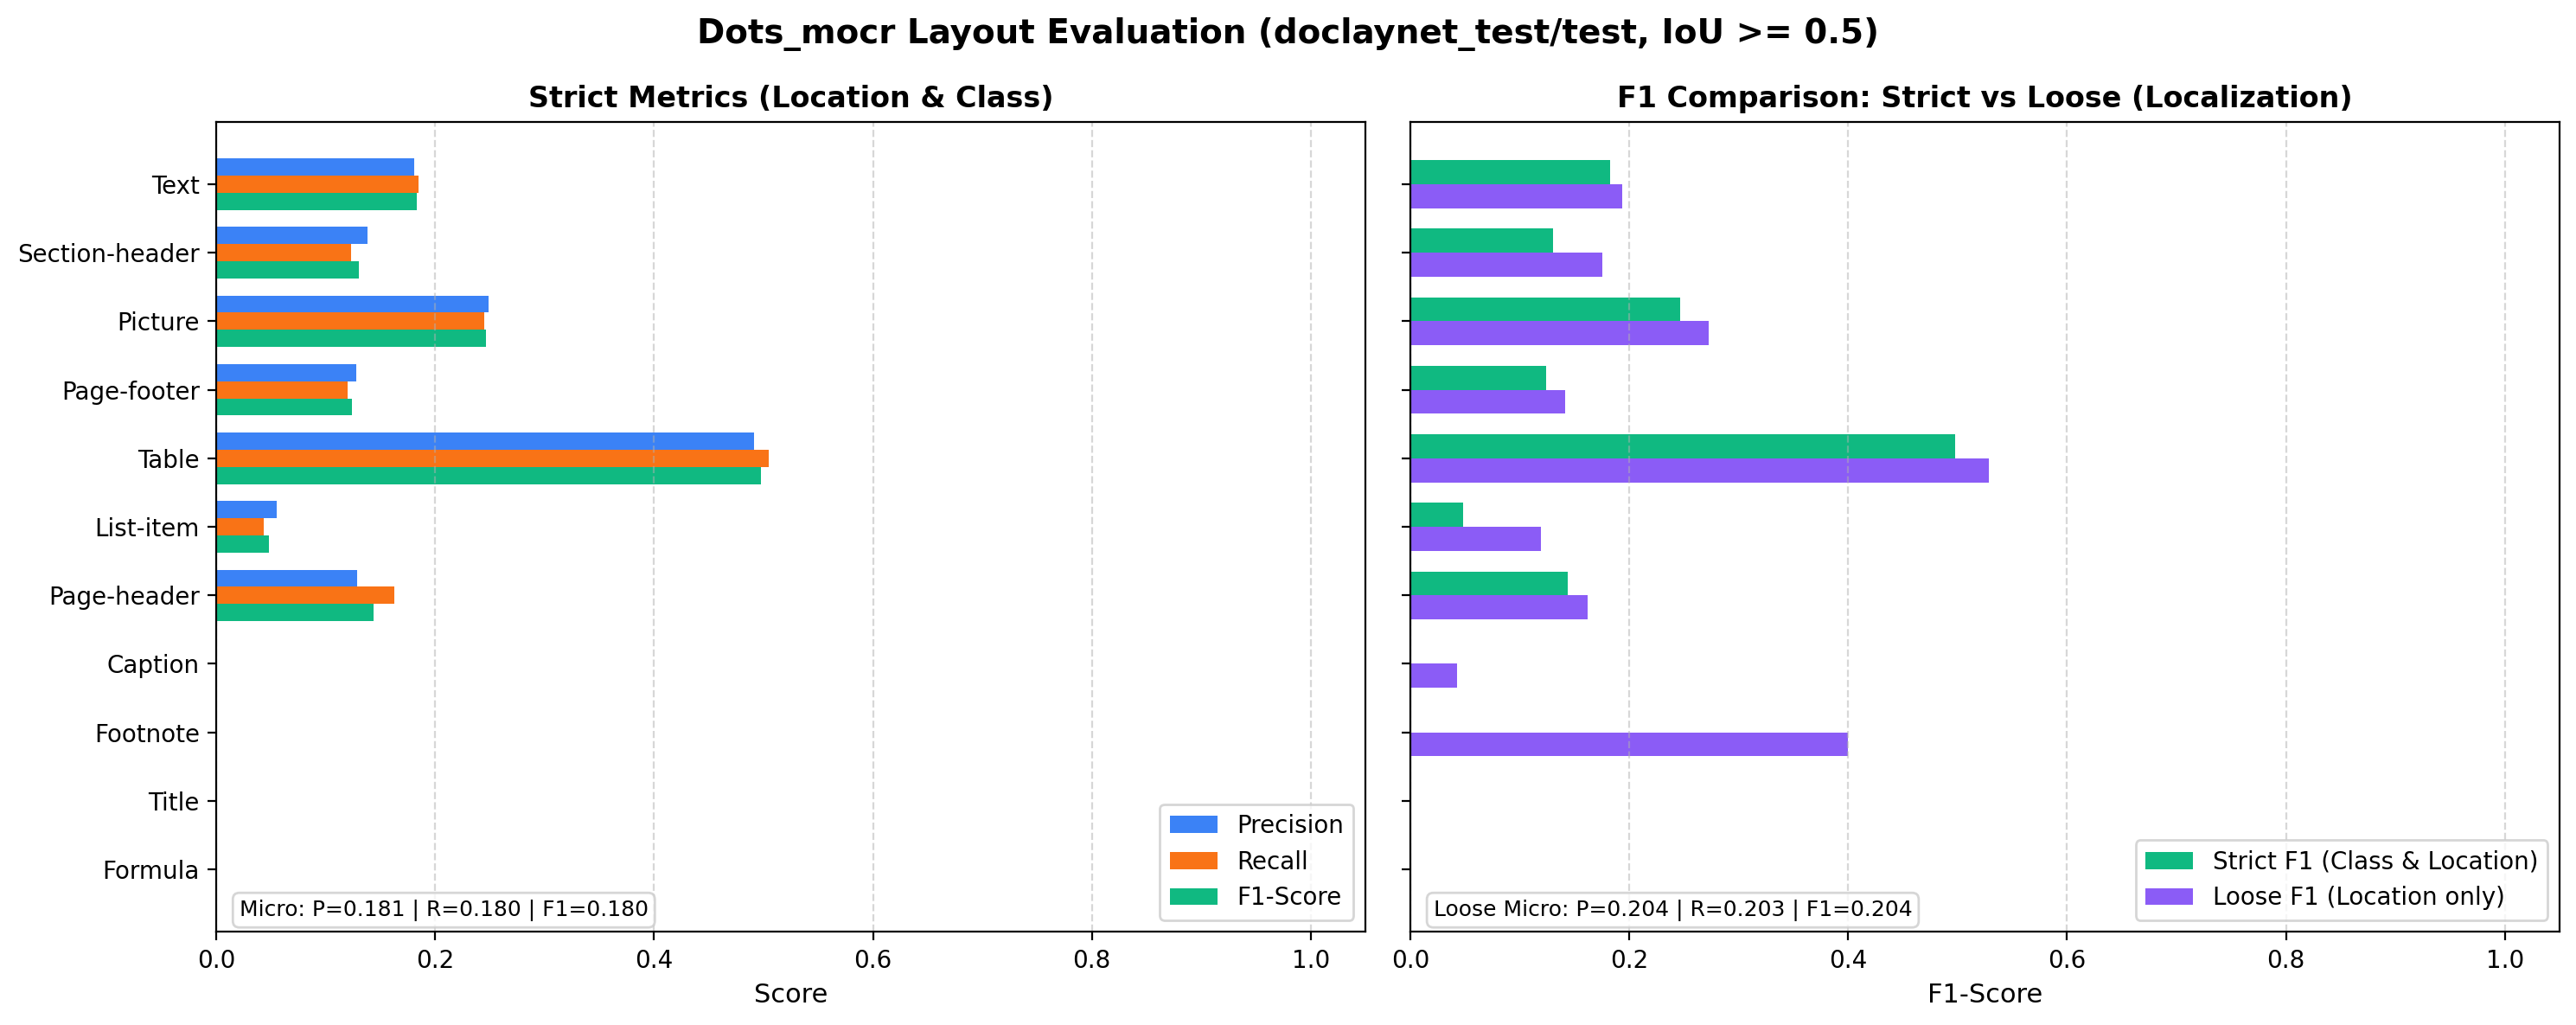

In [4]:
eval_script = ROOT / "scripts" / "evaluate_predictions.py"
chart_path = FIGURES_DIR / "metrics_chart.png"
chart_path.parent.mkdir(parents=True, exist_ok=True)

cmd = [
    sys.executable,
    str(eval_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--iou-threshold", str(IOU_THRESHOLD),
    "--allow-incomplete",
    "--loose",
    "--plot", str(chart_path),
]

print("Running evaluation:")
env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8"}
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), env=env, encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])

if chart_path.exists():
    from IPython.display import Image, display
    print(f"\nEvaluation Chart ({chart_path}):")
    display(Image(filename=str(chart_path)))


## 3. Ground Truth vs. Prediction Examples

Vẽ bounding box Ground Truth (bên trái) đối chiếu với dự đoán của dots.mocr (bên phải) cạnh nhau trên cùng một ảnh để trực quan hóa chất lượng nhận diện layout.

Running: C:\Users\thien\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\visualize_predictions.py --method dots_mocr --dataset doclaynet_test --split test --limit 4 --output-dir D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\dots_mocr_doclaynet_test
[viz] Ve 4 anh (dots_mocr vs ground truth | box_only=False) tu D:\Semester_261\DoAnChuyenNganh\DO-AN-261\visualization\scripts\..\..\outputs\predictions\dots_mocr\doclaynet_test
  [ok] 1.png
  [ok] 2.png
  [ok] 3.png
  [ok] 4.png
[viz] Xong. Anh luu tai D:\Semester_261\DoAnChuyenNganh\DO-AN-261\outputs\reports\dots_mocr_doclaynet_test

Hiển thị 4 ảnh mẫu đối chiếu (Ground Truth vs dots_mocr):


• Ảnh 1.png:


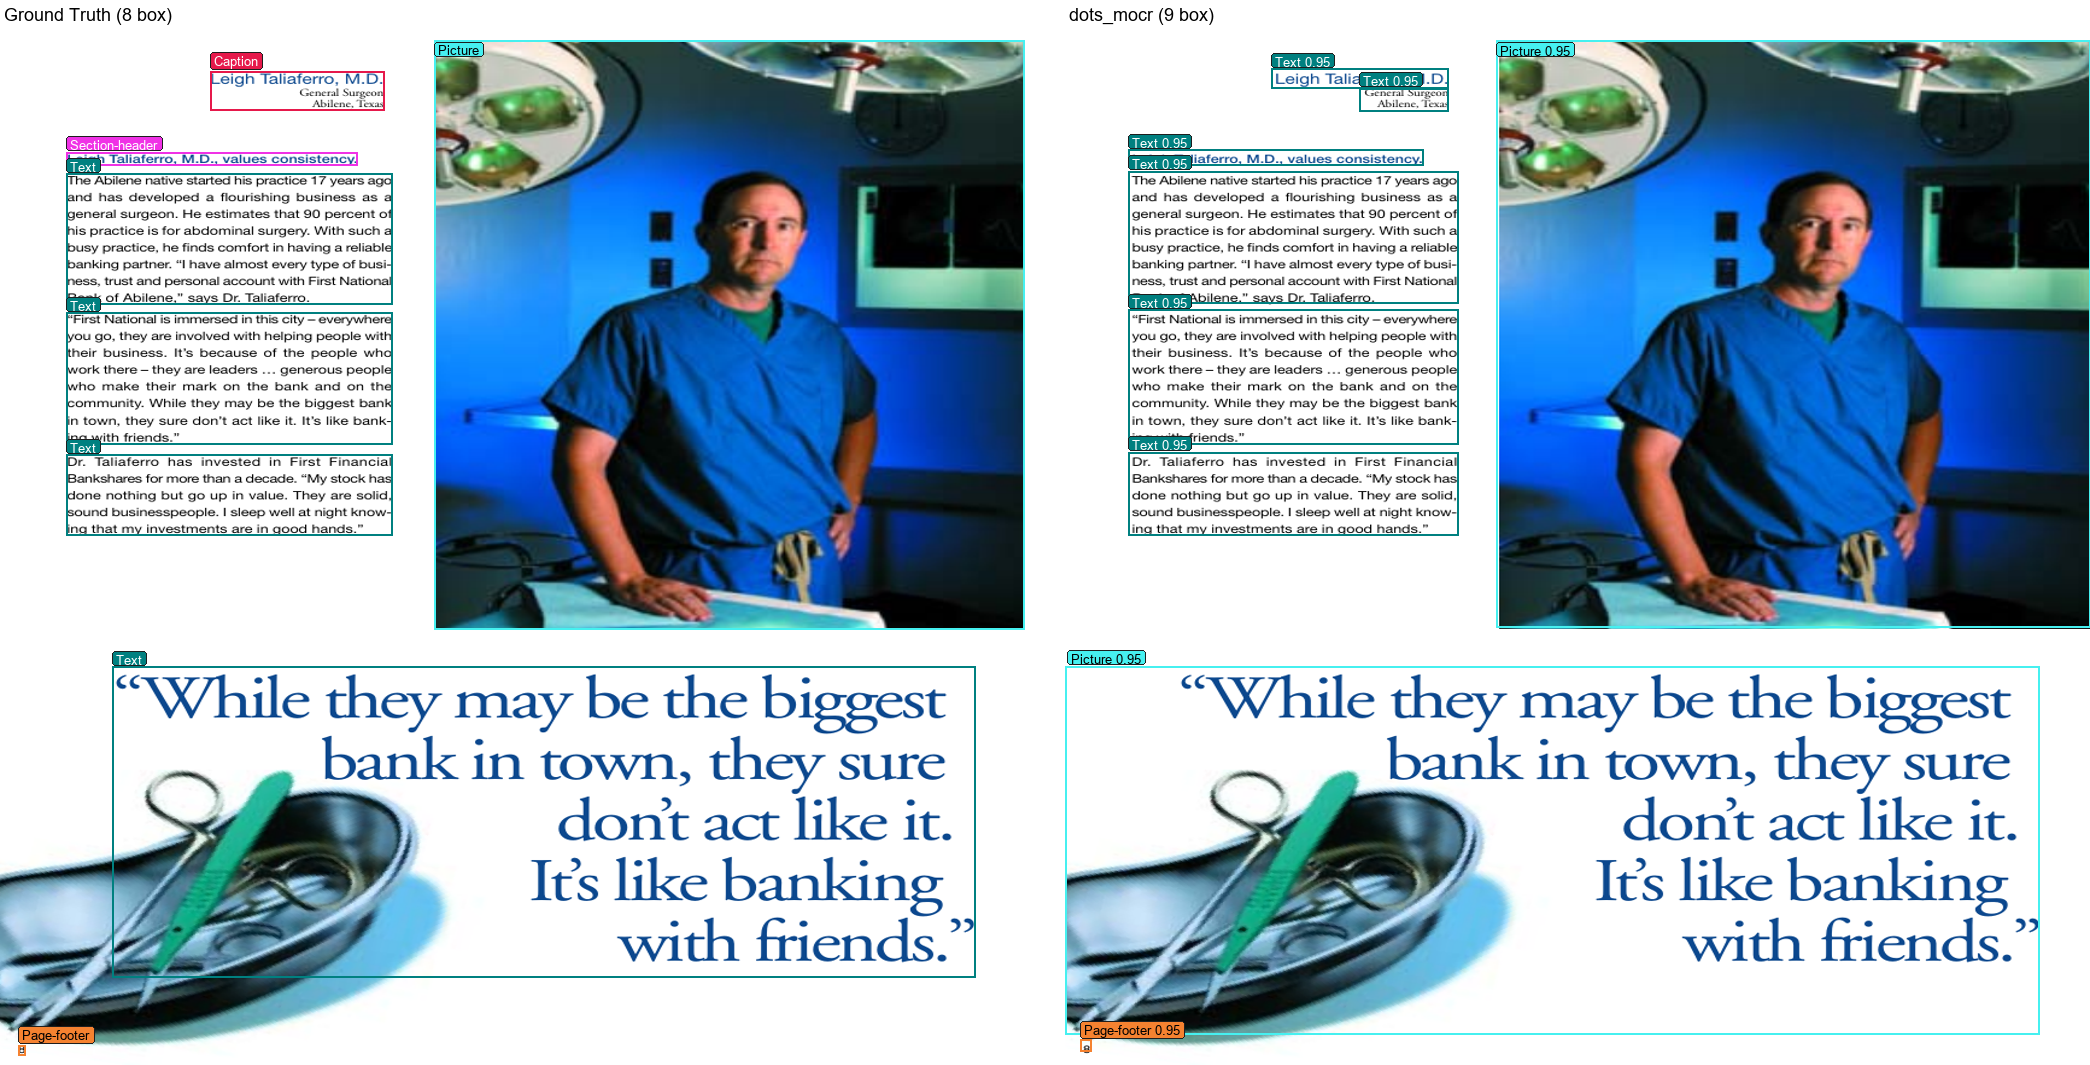

• Ảnh 2.png:


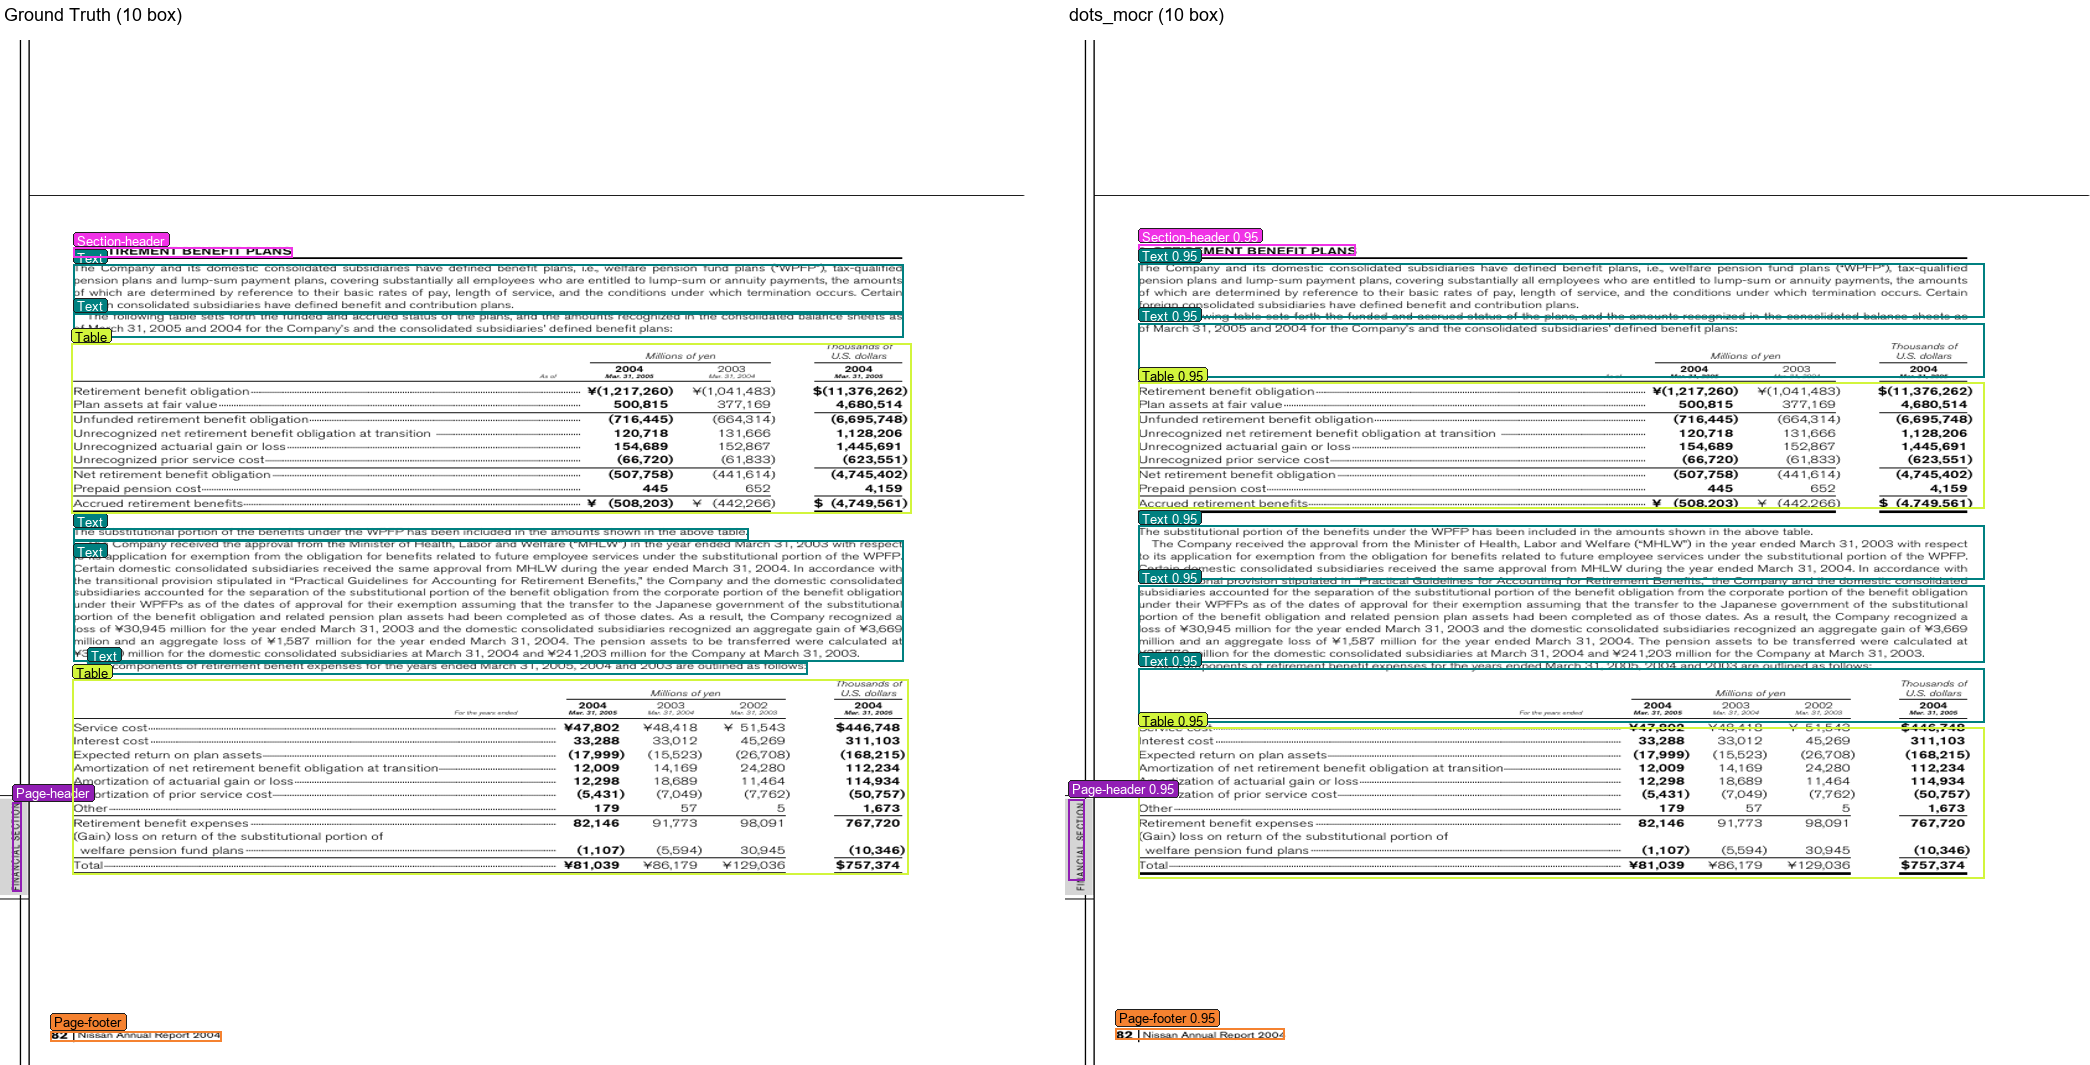

• Ảnh 3.png:


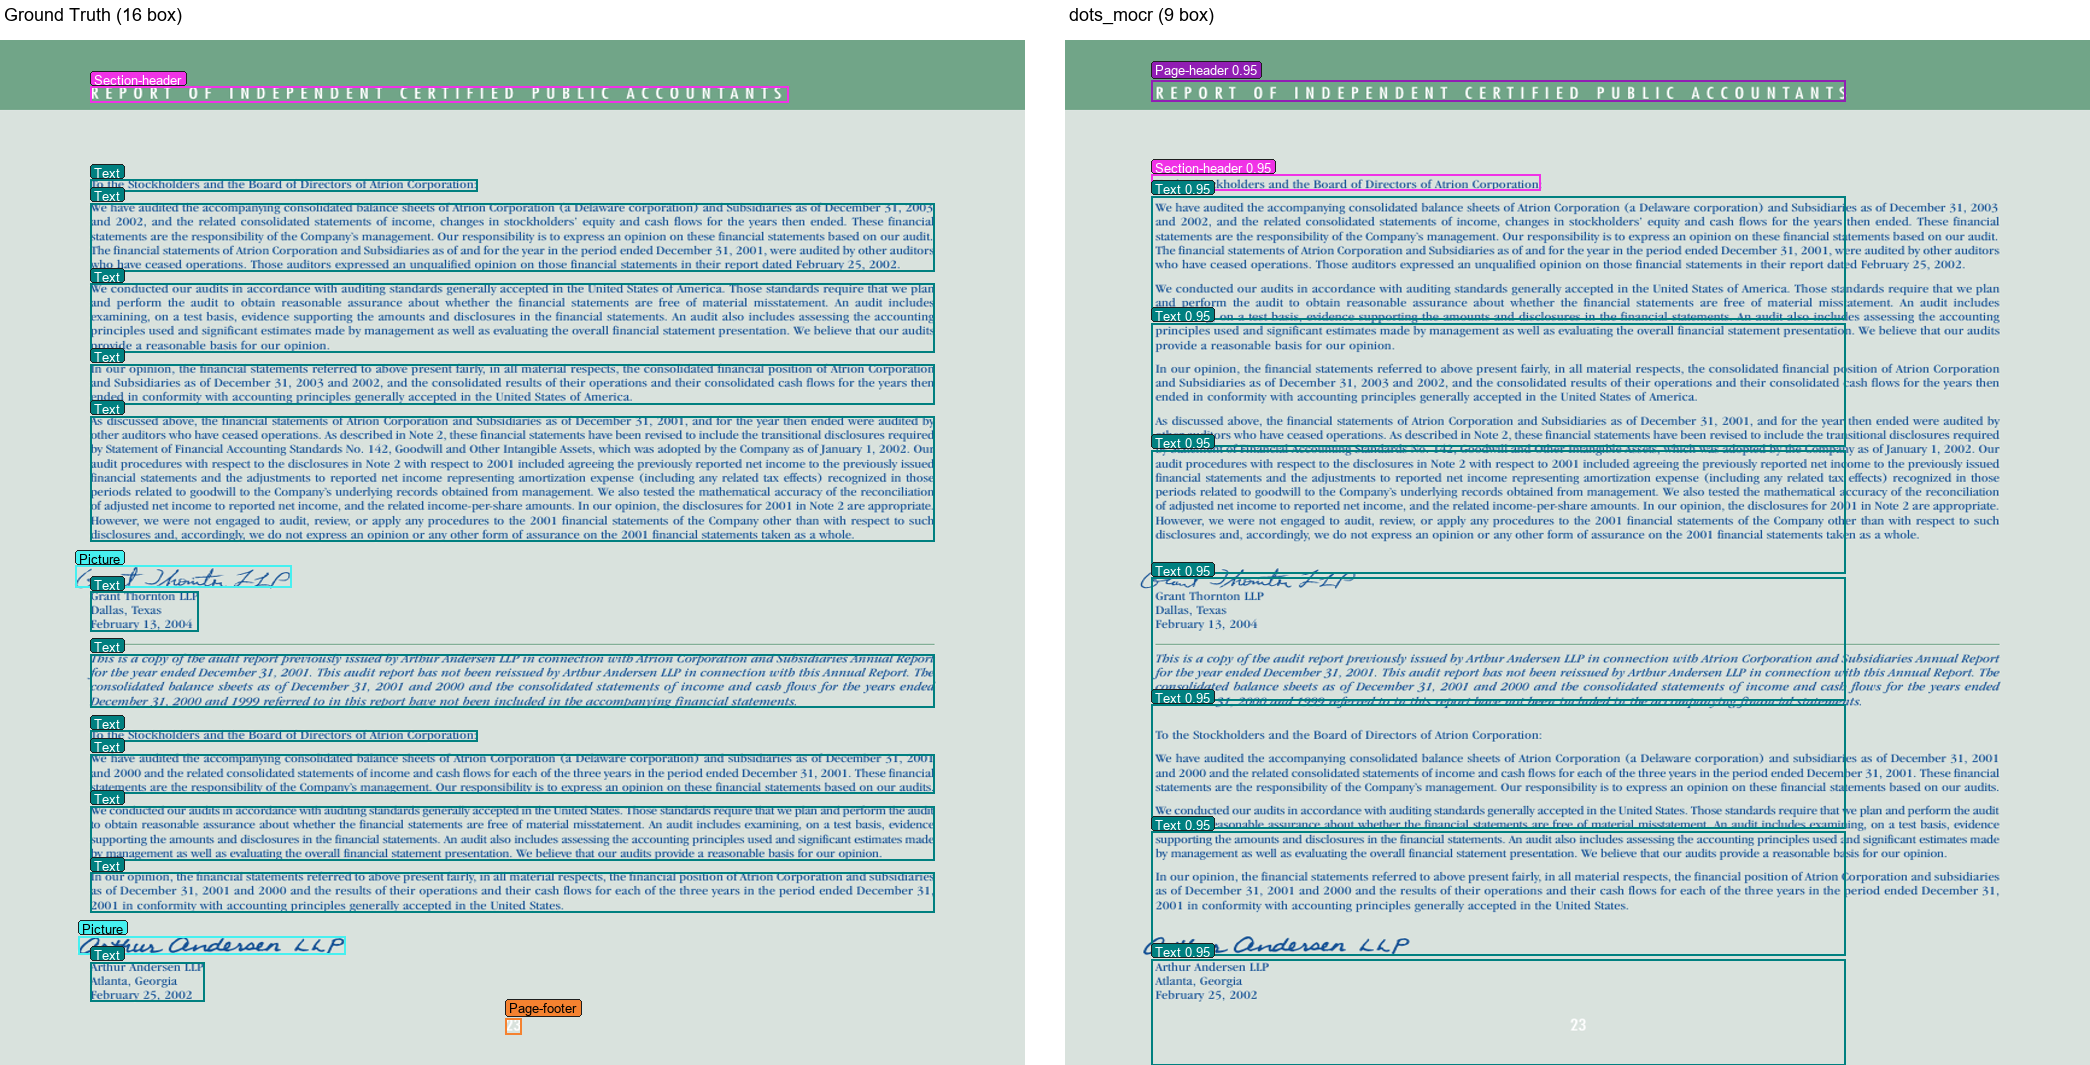

• Ảnh 4.png:


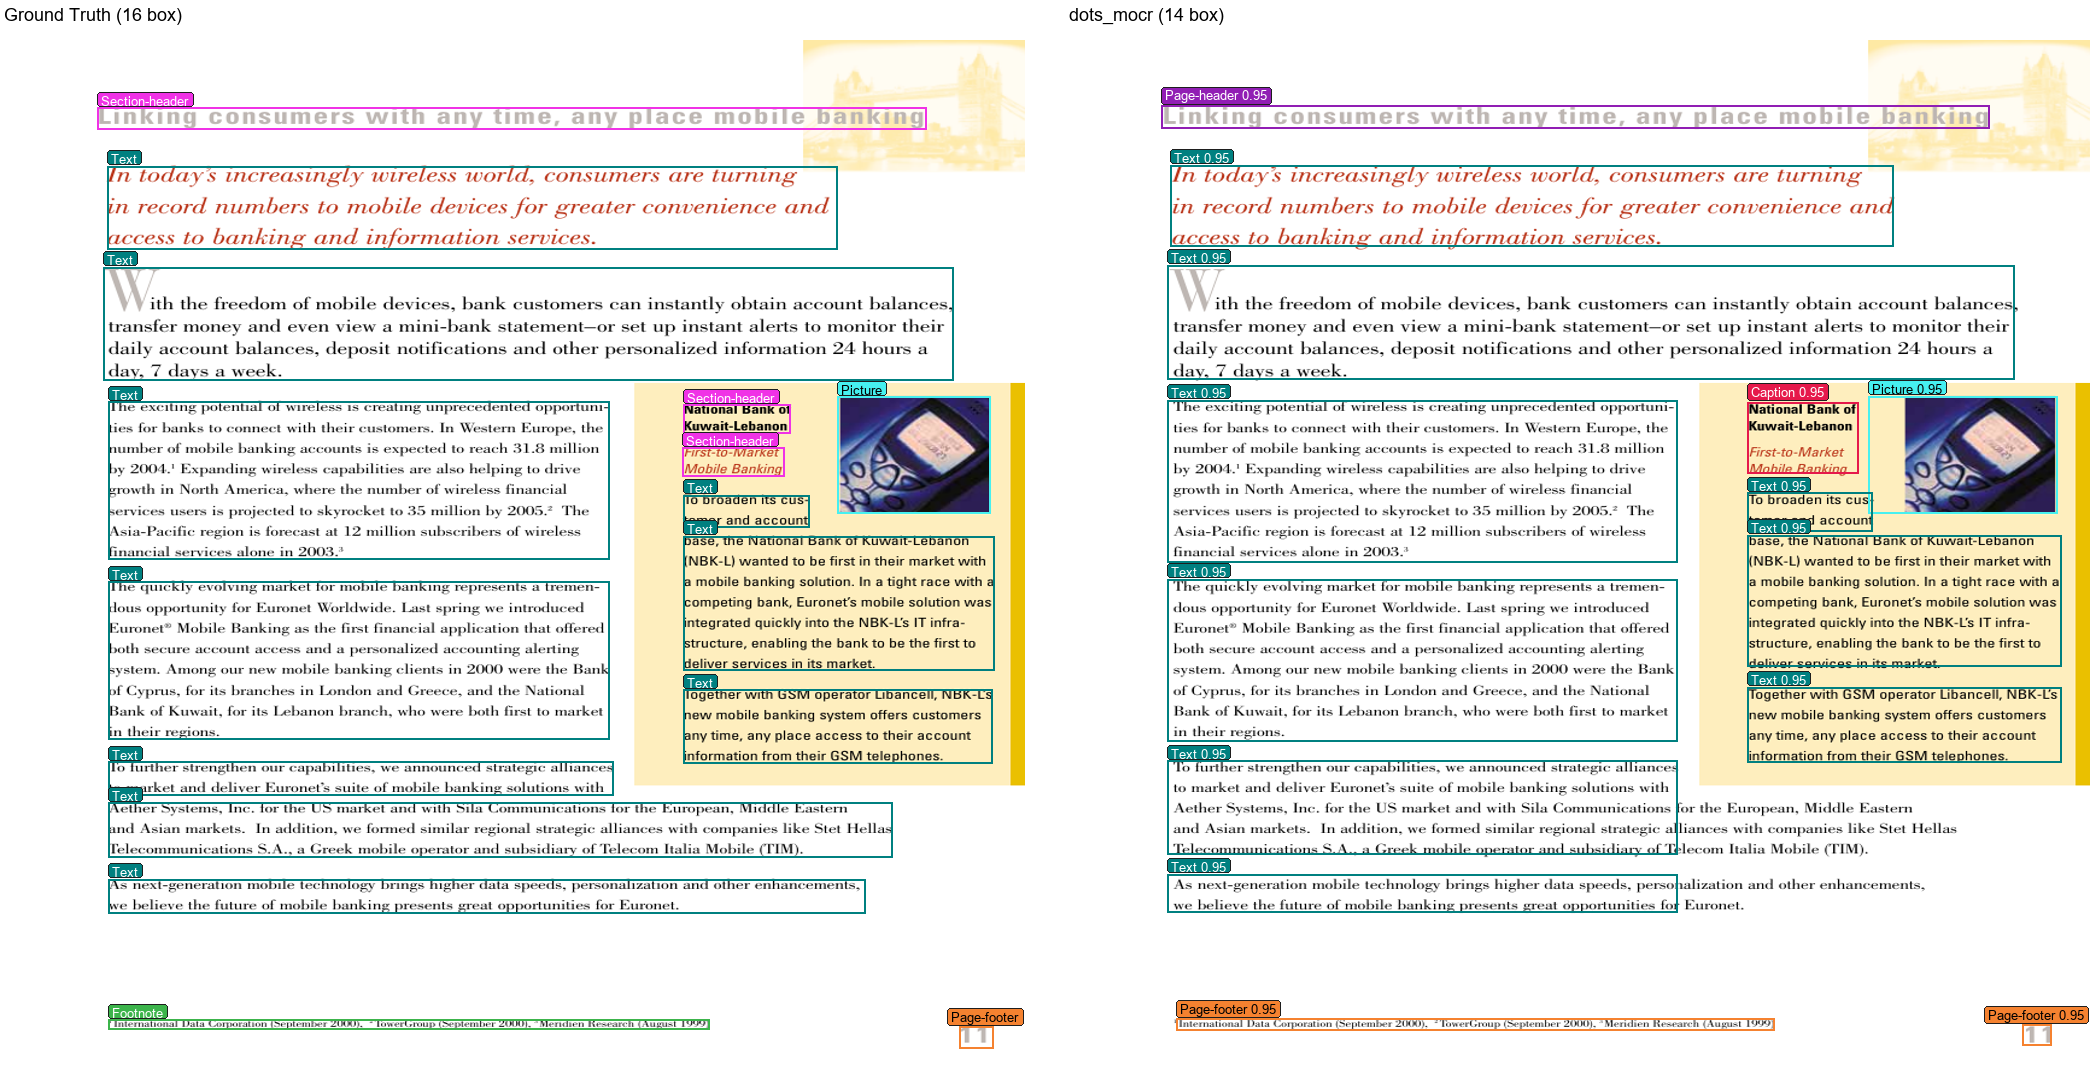

In [5]:
viz_script = ROOT / "visualization" / "scripts" / "visualize_predictions.py"
cmd = [
    sys.executable,
    str(viz_script),
    "--method", METHOD,
    "--dataset", DATASET,
    "--split", SPLIT,
    "--limit", str(FIGURE_LIMIT),
    "--output-dir", str(FIGURES_DIR),
]

print(f"Running: {' '.join(cmd)}")
env = {**os.environ, "PYTHONUNBUFFERED": "1", "PYTHONIOENCODING": "utf-8"}
res = subprocess.run(cmd, capture_output=True, text=True, cwd=str(ROOT), env=env, encoding="utf-8", errors="replace")
print(res.stdout)
if res.stderr:
    print("Errors / Warnings:", res.stderr[-500:])

from IPython.display import Image, display

fig_files = sorted(
    (p for p in FIGURES_DIR.glob("*.png") if p.stem.isdigit()),
    key=lambda p: int(p.stem),
)
sample_files = fig_files[:4]
print(f"\nHiển thị {len(sample_files)} ảnh mẫu đối chiếu (Ground Truth vs {METHOD}):")
for f in sample_files:
    print(f"• Ảnh {f.name}:")
    display(Image(filename=str(f)))
